# Snap-through of a shallow cylindrical roof
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/meyer-nils/torch-fem/blob/main/examples/basic/planar/snap_through.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/meyer-nils/torch-fem/main?labpath=examples/basic/planar/snap_through.ipynb)

The hinged shallow cylindrical roof under a central point load is a classical verification problem for geometrically nonlinear analysis. Its equilibrium path has a limit point: beyond a critical load the structure snaps through to a far, inverted configuration, and the branch in between has negative stiffness.

A load-controlled solve cannot follow that branch, because above the limit load there is no equilibrium near the current state. Viscous stabilization supplies the missing stiffness through the `alpha` argument of `solve()`, which adds a damping force $\alpha \mathbf{M} \Delta \mathbf{u} / \Delta \lambda$ to the residual and its tangent. The solve then crosses the valley instead of tracing it, which is what the Abaqus `*STATIC, STABILIZE` option does. The arc-length method of `solve_arc_length()` instead treats the load factor as an unknown and bounds the length of each step, so it traces the branch itself, like the Abaqus `*STATIC, RIKS` option.

Geometry and material follow the benchmark of Sabir and Lock, taken here as a **plane strain section** so the model is a shallow arch rather than the full shell panel. Loads are therefore per unit depth.

In [1]:
import matplotlib.pyplot as plt
import torch

from torchfem import Planar
from torchfem.materials import HyperelasticPlaneStrain

torch.set_default_dtype(torch.float64)

## Material 

We use a Neo-Hookean strain energy density in a hyperelastic plane-strain material.

In [2]:
def psi(F, params):
    """Neo-Hookean strain energy density."""
    G, D = params[0], params[1]
    C = F.transpose(-1, -2) @ F
    J = torch.exp(0.5 * torch.logdet(C))
    C_bar = C * J ** (-2.0 / 3.0)
    return G * (torch.trace(C_bar) - 3.0) + 1 / D * (J - 1) ** 2


# Neo-Hookean parameters matched to E and nu
E = 3102.75
NU = 0.3
mu = E / (2 * (1 + NU))
kappa = E / (3 * (1 - 2 * NU))
material = HyperelasticPlaneStrain(psi, params=[mu / 2, 2.0 / kappa])

## Geometry

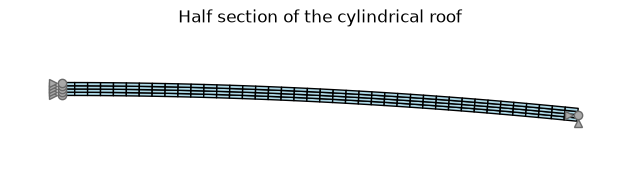

In [3]:
# Geometry and mesh parameters
R = 2540.0
THETA = 0.1
T = 6.35
N_ARC = 40
N_T = 4

# Nodes on concentric arcs through the thickness, crown at phi=0
phi = torch.linspace(0.0, THETA, N_ARC + 1)
y0 = R * torch.cos(torch.tensor(THETA))
nodes = torch.cat(
    [
        torch.stack([r * torch.sin(phi), r * torch.cos(phi) - y0], dim=-1)
        for r in torch.linspace(R - T / 2, R + T / 2, N_T + 1)
    ]
)

npl = N_ARC + 1
elements = torch.tensor(
    [
        [j * npl + i, j * npl + i + 1, (j + 1) * npl + i + 1, (j + 1) * npl + i]
        for j in range(N_T)
        for i in range(N_ARC)
    ]
)

# Node columns: crown at phi=0, hinge on the mid-surface at phi=THETA
col = torch.arange(len(nodes)) % npl
row = torch.arange(len(nodes)) // npl
crown = col == 0
hinge = (col == N_ARC) & (row == N_T // 2)

roof = Planar(nodes, elements, material)
roof.thickness = torch.ones(len(elements))
roof.constraints[hinge] = True  # hinged support
roof.constraints[crown, 0] = True  # symmetry plane

roof.plot(title="Half section of the cylindrical roof")

## Reference equilibrium path

Prescribing the crown displacement makes the problem stable, so the full path including the descending branch can be traced. This is the reference the load-controlled solve is compared against.

In [4]:
# Apply boundary conditions: crown node is displaced downward by 30 mm
roof.constraints[crown, 1] = True
roof.displacements[crown, 1] = -30.0


# Solve
increments = torch.linspace(0, 1, 31)
u_ref, f_ref, _, _, _ = roof.solve(
    increments=increments, return_intermediate=True, verbose=True
)

# Postprocess results
w_ref = -u_ref[:, crown, 1].mean(dim=1)
P_ref = -f_ref[:, crown, 1].sum(dim=1) * 2.0  # half model -> full arch

# Limit point: first point where the path stops rising
descending = torch.nonzero((P_ref[1:] - P_ref[:-1]) < 0).ravel()
i_limit = int(descending[0])
P_limit = float(P_ref[i_limit])

────────────────────────────────────────────────────────────────────────────────────────
 model    Planar · 160 elem · 410 dof · float64
 machine  x86_64 · 14 threads · 61 GB RAM
 solver   direct · scipy · cpu
 newton   rtol 1e-08 · atol 1e-06 · <=10 it · finite strain
────────────────────────────────────────────────────────────────────────────────────────
  Increment  Load factor  Steps  Newton  Krylov  Residual  Wall time


          1      0.03333      1       4       -  2.92e-11     1.50 s
          2      0.06667      1       2       -  2.55e-07     0.11 s


          3          0.1      1       2       -  3.69e-07     0.11 s


          4       0.1333      1       2       -  9.61e-07     0.69 s


          5       0.1667      1       3       -  2.63e-11     0.25 s
          6          0.2      1       3       -  2.92e-11     0.08 s
          7       0.2333      1       3       -  2.82e-11     0.11 s


          8       0.2667      1       3       -  2.97e-11     0.86 s
          9          0.3      1       3       -  3.01e-11     0.16 s


... (3 outputs left out)

         19       0.6333      1       5       -  3.75e-11     0.11 s
         20       0.6667      1       4       -  8.60e-11     0.09 s
         21          0.7      1       5       -  2.66e-11     0.11 s


         22       0.7333      1       4       -  2.67e-11     0.09 s
         23       0.7667      1       3       -  8.71e-09     0.07 s
         24          0.8      1       3       -  5.30e-11     0.07 s


         25       0.8333      1       3       -  2.77e-11     0.07 s
         26       0.8667      1       3       -  2.86e-11     0.07 s
         27          0.9      1       3       -  2.44e-11     0.07 s


         28       0.9333      1       2       -  2.93e-07     0.06 s
         29       0.9667      1       2       -  9.13e-08     0.07 s
         30            1      1       2       -  3.48e-08     0.06 s
────────────────────────────────────────────────────────────────────────────────────────
 converged · 30 increments · 93 Newton iterations · 5.54 s


## Load control with stabilization

The same model is reused with the crown displacement released and a point load applied instead, ramped to twice the limit load. Viscous damping keeps the tangent stiffness invertible while the arch traverses the unstable region, and the solve ends on the far branch.

Setting `alpha=0` here makes the solve fail: without the damping term there is no equilibrium near the limit point for Newton-Raphson to find, and subdividing the increment only moves closer to the singular tangent.

In [5]:
# Ramp up to twice the limit load
load = 2.0 * P_limit

# Swap displacement control for load control on the same model
roof.constraints[crown, 1] = False
roof.displacements[crown, 1] = 0.0
roof.forces[crown, 1] = -(load / 2.0) / int(crown.sum())  # half model

# Solve with stabilization
u, _, _, _, _ = roof.solve(
    increments=increments,
    alpha=1e-6,
    return_intermediate=True,
    verbose=True,
)

# Postprocess results
w = -u[:, crown, 1].mean(dim=1)
P = increments * load

────────────────────────────────────────────────────────────────────────────────────────
 model    Planar · 160 elem · 410 dof · float64
 machine  x86_64 · 14 threads · 61 GB RAM
 solver   direct · scipy · cpu
 newton   rtol 1e-08 · atol 1e-06 · <=10 it · finite strain · stabilized alpha=1e-06
────────────────────────────────────────────────────────────────────────────────────────
  Increment  Load factor  Steps  Newton  Krylov  Residual  Wall time


          1      0.03333      1       3       -  1.28e-10     0.08 s
          2      0.06667      1       2       -  2.68e-08     0.06 s
          3          0.1      1       2       -  8.35e-09     0.06 s


          4       0.1333      1       2       -  1.25e-08     0.07 s


          5       0.1667      1       2       -  2.19e-08     0.07 s
          6          0.2      1       2       -  4.06e-08     0.06 s
          7       0.2333      1       2       -  7.96e-08     0.07 s


          8       0.2667      1       2       -  1.67e-07     0.07 s


          9          0.3      1       2       -  3.84e-07     0.07 s
         10       0.3333      1       2       -  9.87e-07     0.09 s


... (7 outputs left out)

         22       0.7333      1       2       -  2.30e-11     0.63 s


         23       0.7667      1       2       -  2.41e-11     0.26 s
         24          0.8      1       2       -  2.45e-11     0.06 s
         25       0.8333      1       2       -  2.24e-11     0.10 s


         26       0.8667      1       2       -  2.78e-11     0.09 s
         27          0.9      1       2       -  2.31e-11     0.09 s
         28       0.9333      1       2       -  2.17e-11     0.08 s


         29       0.9667      1       2       -  2.57e-11     0.08 s
         30            1      1       2       -  2.41e-11     0.07 s
────────────────────────────────────────────────────────────────────────────────────────
 converged · 30 increments · 107 Newton iterations · 4.26 s


## Arc-length control

The forces now define a load pattern, a unit load on the full arch, which the load factor $\lambda$ scales. Each step moves a distance $\Delta s$ in displacement space, $\Delta \mathbf{u} \cdot \Delta \mathbf{u} = \Delta s^2$, while $\lambda$ adjusts to keep the arch in equilibrium. As in Abaqus, $\Delta s$ is set by the load factor increment of the first step, here 0.25 N/mm. Past the limit point, $\lambda$ decreases along the descending branch instead of jumping across it. The path ends once a displacement reaches the 30 mm of the reference.

In [6]:
# Unit load on the full arch, scaled by the load factor
roof.forces[crown, 1] = -0.5 / int(crown.sum())  # half model

# Solve with arc-length control
u_arc, _, _, _, _, lam = roof.solve_arc_length(
    0.25, 100, max_displacement=30.0, verbose=True
)

# Postprocess results
w_arc = -u_arc[:, crown, 1].mean(dim=1)
P_arc = lam

────────────────────────────────────────────────────────────────────────────────────────
 model    Planar · 160 elem · 410 dof · float64
 machine  x86_64 · 14 threads · 61 GB RAM
 solver   direct · scipy · cpu
 newton   rtol 1e-08 · atol 1e-06 · <=10 it · finite strain · load increment 0.25
────────────────────────────────────────────────────────────────────────────────────────
       Step  Load factor  Steps  Newton  Krylov  Residual  Wall time


          1       0.2364      1       2       -  7.73e-11     1.10 s


          2       0.4466      1       2       -  5.47e-11     0.71 s


          3        0.632      1       2       -  9.72e-11     0.71 s


          4        0.794      1       2       -  2.05e-10     0.24 s
          5       0.9341      1       2       -  3.98e-10     0.11 s


          6        1.054      1       2       -  7.12e-10     0.11 s
          7        1.155      1       2       -  1.13e-09     0.11 s


... (38 outputs left out)

         69         1.88      1       2       -  4.77e-11     0.43 s


         70        2.267      1       2       -  3.82e-11     0.65 s


         71        2.683      1       2       -  2.89e-11     0.22 s
         72         3.13      1       2       -  2.60e-11     0.06 s
         73        3.608      1       2       -  2.35e-11     0.08 s


         74        4.119      1       2       -  2.35e-11     0.11 s
────────────────────────────────────────────────────────────────────────────────────────
 converged · 74 steps · 152 Newton iterations · 17.85 s


## Comparison

The stabilized solve follows the reference path up to the limit point, cuts across the valley at nearly constant load instead of descending into it, and rejoins the reference on the far branch. The descending branch itself is never visited, which is the price of load control. How far the damping perturbs the result is measured by `roof.stabilization_energy`, which should stay small compared to the work done by the external load.

The arc-length solve follows the reference along the whole path, including the descending branch, although only the load is prescribed.

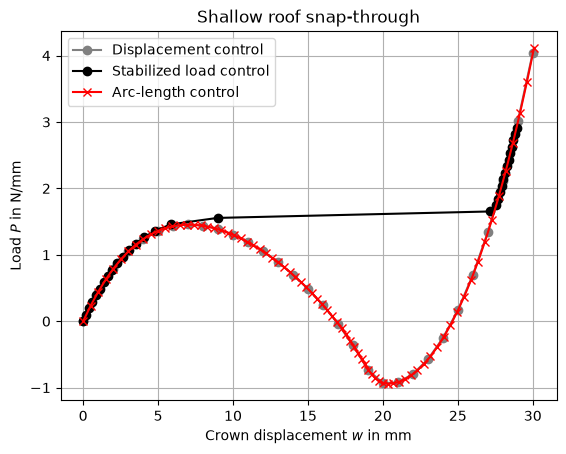

In [7]:
plt.plot(w_ref, P_ref, "o-", color="gray", label="Displacement control")
plt.plot(w, P, "o-", color="black", label="Stabilized load control")
plt.plot(w_arc, P_arc, "x-", color="red", label="Arc-length control")
plt.xlabel("Crown displacement $w$ in mm")
plt.ylabel("Load $P$ in N/mm")
plt.title("Shallow roof snap-through")
plt.legend()
plt.grid()